# 02 - Model baseline, pengulangan 10 pembagian, dan ablasi fitur
Memuat `features.npz` dari notebook 01. Logistic Regression dan Random Forest pada fitur CNN, fitur tekstur-frekuensi, dan gabungannya;
ambang dipilih dari EER pada validasi, metrik APCER/BPCER/HTER/AUC pada test; 10 pembagian per subjek (seed 0-9) dengan uji Wilcoxon berpasangan.
Keluaran: `results_stage1.csv`, `results_repeated.csv`, `results_ablation.csv`, gambar HTER dan ROC.
Kode tidak diubah setelah dijalankan.

In [1]:
import numpy as np, pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import roc_auc_score, roc_curve
from google.colab import drive; drive.mount('/content/drive')

WORK = '/content/drive/MyDrive/Dataset_CelebA-Spoof/work'
d = np.load(f'{WORK}/features.npz', allow_pickle=True)
keep = d['ok'] == 1
Xc, Xf, y, subj, sp = [d[k][keep] for k in ['Xc', 'Xf', 'y', 'subject', 'split']]
Xfu = np.hstack([Xc, Xf])
tr, va, te = sp == 'train', sp == 'val', sp == 'test'
print('dipakai:', keep.sum(), '| tak terbaca:', (~keep).sum())

def rates(y, s, t):
    pred = (s >= t).astype(int)
    apcer = ((pred == 0) & (y == 1)).sum() / max((y == 1).sum(), 1)   # serangan lolos
    bpcer = ((pred == 1) & (y == 0)).sum() / max((y == 0).sum(), 1)   # live ditolak
    return apcer, bpcer, (apcer + bpcer) / 2

def eer_threshold(y, s):
    fpr, tpr, thr = roc_curve(y, s)
    return thr[np.nanargmin(np.abs(fpr - (1 - tpr)))]

def evaluate(name, model, X):
    model.fit(X[tr], y[tr])
    s_va, s_te = model.predict_proba(X[va])[:, 1], model.predict_proba(X[te])[:, 1]
    t = eer_threshold(y[va], s_va)            # ambang dipilih di VAL, bukan di test
    a, b, h = rates(y[te], s_te, t); a5, b5, h5 = rates(y[te], s_te, 0.5)
    return dict(model=name, AUC=roc_auc_score(y[te], s_te), thr_val=t,
                APCER=a, BPCER=b, HTER=h, HTER_thr05=h5)

mk_lr = lambda: Pipeline([('sc', StandardScaler()), ('m', LogisticRegression(max_iter=2000, class_weight='balanced'))])
mk_rf = lambda: RandomForestClassifier(n_estimators=300, min_samples_leaf=2, class_weight='balanced', n_jobs=-1, random_state=42)

res = [evaluate('Baseline (Dummy)', DummyClassifier(strategy='prior'), Xc),
       evaluate('LR | CNN', mk_lr(), Xc),
       evaluate('LR | Frekuensi', mk_lr(), Xf),
       evaluate('LR | CNN+Frekuensi', mk_lr(), Xfu),
       evaluate('RF | CNN', mk_rf(), Xc),
       evaluate('RF | CNN+Frekuensi', mk_rf(), Xfu)]
out = pd.DataFrame(res).round(3); print(out)
out.to_csv(f'{WORK}/results_stage1.csv', index=False)

Mounted at /content/drive
dipakai: 8511 | tak terbaca: 1
                model    AUC  thr_val  APCER  BPCER   HTER  HTER_thr05
0    Baseline (Dummy)  0.500      inf  1.000  0.000  0.500       0.500
1            LR | CNN  0.990    0.061  0.010  0.142  0.076       0.049
2      LR | Frekuensi  0.940    0.510  0.100  0.186  0.143       0.147
3  LR | CNN+Frekuensi  0.994    0.293  0.029  0.055  0.042       0.046
4            RF | CNN  0.981    0.560  0.069  0.084  0.077       0.100
5  RF | CNN+Frekuensi  0.982    0.535  0.059  0.099  0.079       0.094


In [2]:
from scipy.stats import wilcoxon
from sklearn.model_selection import GridSearchCV, GroupKFold
import warnings; warnings.filterwarnings('ignore')

subjects = np.unique(subj)
def split_by_subject(seed):
    ids = np.random.RandomState(seed).permutation(subjects); n = len(ids)
    trs, vas = ids[:int(.70*n)], ids[int(.70*n):int(.85*n)]
    tr_, va_ = np.isin(subj, trs), np.isin(subj, vas)
    return tr_, va_, ~(tr_ | va_)

def run(model, X, tr_, va_, te_):
    model.fit(X[tr_], y[tr_])
    s_va, s_te = model.predict_proba(X[va_])[:, 1], model.predict_proba(X[te_])[:, 1]
    t = eer_threshold(y[va_], s_va)
    a, b, h = rates(y[te_], s_te, t)
    return roc_auc_score(y[te_], s_te), a, b, h

def tuned_lr(groups):
    g = GridSearchCV(mk_lr(), {'m__C': [0.003, 0.03, 0.3, 3]}, scoring='roc_auc', cv=GroupKFold(3))
    class W:
        def fit(s, X, yy): g.fit(X, yy, groups=groups); return s
        def predict_proba(s, X): return g.predict_proba(X)
    return W()

rows = []
for seed in range(10):
    tr_, va_, te_ = split_by_subject(seed)
    if len(set(y[va_])) < 2 or len(set(y[te_])) < 2: continue
    for name, X in [('CNN', Xc), ('CNN+Frek', Xfu)]:
        for mode in ['default', 'tuned']:
            mdl = mk_lr() if mode == 'default' else tuned_lr(subj[tr_])
            auc, a, b, h = run(mdl, X, tr_, va_, te_)
            rows.append(dict(seed=seed, fitur=name, mode=mode, AUC=auc, APCER=a, BPCER=b, HTER=h))
R = pd.DataFrame(rows)
print(R.groupby(['mode', 'fitur'])[['AUC', 'APCER', 'BPCER', 'HTER']].agg(['mean', 'std']).round(3))
for mode in ['default', 'tuned']:
    p = R[R['mode'] == mode].pivot(index='seed', columns='fitur', values='HTER')
    print(mode, '| rata-rata HTER CNN - Fusi:', round((p['CNN'] - p['CNN+Frek']).mean(), 4),
          '| Wilcoxon p =', round(wilcoxon(p['CNN'], p['CNN+Frek']).pvalue, 4), '| n =', len(p))
R.to_csv(f'{WORK}/results_repeated.csv', index=False)

                    AUC         APCER         BPCER          HTER       
                   mean    std   mean    std   mean    std   mean    std
mode    fitur                                                           
default CNN       0.959  0.028  0.106  0.092  0.095  0.027  0.101  0.042
        CNN+Frek  0.973  0.021  0.085  0.095  0.079  0.026  0.082  0.042
tuned   CNN       0.964  0.024  0.096  0.077  0.094  0.037  0.095  0.035
        CNN+Frek  0.975  0.020  0.081  0.094  0.074  0.026  0.078  0.044
default | rata-rata HTER CNN - Fusi: 0.0184 | Wilcoxon p = 0.002 | n = 10
tuned | rata-rata HTER CNN - Fusi: 0.0175 | Wilcoxon p = 0.0137 | n = 10


                AUC         APCER         BPCER          HTER       
               mean    std   mean    std   mean    std   mean    std
varian                                                              
CNN           0.959  0.028  0.106  0.092  0.095  0.027  0.101  0.042
CNN+FFT       0.964  0.026  0.100  0.100  0.089  0.029  0.095  0.043
CNN+FFT+LBP   0.973  0.021  0.085  0.095  0.079  0.026  0.082  0.042
CNN+LBP       0.973  0.018  0.093  0.096  0.082  0.019  0.087  0.046
FFT+LBP saja  0.910  0.023  0.207  0.044  0.151  0.042  0.179  0.023


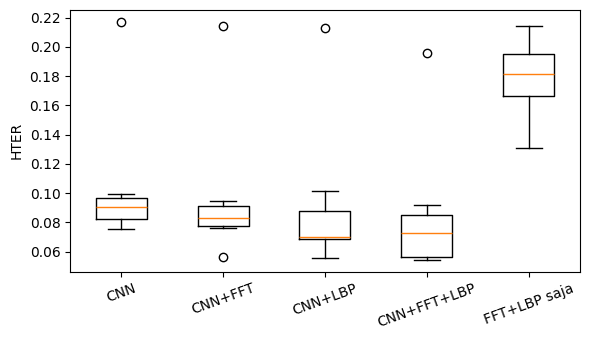

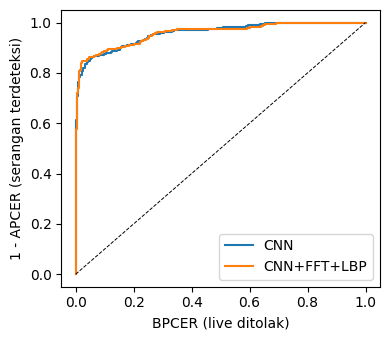

In [3]:
import matplotlib.pyplot as plt, os
os.makedirs(f'{WORK}/figures', exist_ok=True)

variants = {'CNN': Xc, 'CNN+FFT': np.hstack([Xc, Xf[:, :56]]), 'CNN+LBP': np.hstack([Xc, Xf[:, 56:]]),
            'CNN+FFT+LBP': Xfu, 'FFT+LBP saja': Xf}
rows = []
for seed in range(10):
    tr_, va_, te_ = split_by_subject(seed)
    if len(set(y[va_])) < 2 or len(set(y[te_])) < 2: continue
    for name, X in variants.items():
        auc, a, b, h = run(mk_lr(), X, tr_, va_, te_)
        rows.append(dict(seed=seed, varian=name, AUC=auc, APCER=a, BPCER=b, HTER=h))
A = pd.DataFrame(rows)
print(A.groupby('varian')[['AUC', 'APCER', 'BPCER', 'HTER']].agg(['mean', 'std']).round(3))
A.to_csv(f'{WORK}/results_ablation.csv', index=False)

# Gambar 1: sebaran HTER per varian
order = list(variants)
plt.figure(figsize=(6, 3.5))
plt.boxplot([A[A.varian == v].HTER for v in order])
plt.xticks(range(1, len(order) + 1), order, rotation=20); plt.ylabel('HTER')
plt.tight_layout(); plt.savefig(f'{WORK}/figures/fig_hter_ablation.png', dpi=300); plt.show()

# Gambar 2: kurva ROC pada satu pembagian (seed 0)
tr_, va_, te_ = split_by_subject(0)
plt.figure(figsize=(4, 3.5))
for name in ['CNN', 'CNN+FFT+LBP']:
    s_ = mk_lr().fit(variants[name][tr_], y[tr_]).predict_proba(variants[name][te_])[:, 1]
    fpr, tpr, _ = roc_curve(y[te_], s_); plt.plot(fpr, tpr, label=name)
plt.plot([0, 1], [0, 1], 'k--', lw=.7)
plt.xlabel('BPCER (live ditolak)'); plt.ylabel('1 - APCER (serangan terdeteksi)'); plt.legend()
plt.tight_layout(); plt.savefig(f'{WORK}/figures/fig_roc.png', dpi=300); plt.show()

In [4]:
for a_, b_ in [('CNN', 'CNN+LBP'), ('CNN', 'CNN+FFT'), ('CNN+FFT', 'CNN+FFT+LBP'), ('CNN+LBP', 'CNN+FFT+LBP')]:
    p = A.pivot(index='seed', columns='varian', values='HTER')
    print(f'{a_:>8} vs {b_:<12} selisih={(p[a_] - p[b_]).mean():+.4f}  Wilcoxon p={wilcoxon(p[a_], p[b_]).pvalue:.4f}')

p = A.pivot(index='seed', columns='varian', values='HTER')
sd = p['CNN'].idxmax(); print('seed ekstrem:', sd, p.loc[sd].round(3).to_dict())
tr_, va_, te_ = split_by_subject(sd)
print('subjek test:', len(np.unique(subj[te_])), '| live/spoof di test:', (y[te_] == 0).sum(), (y[te_] == 1).sum())
print('subjek tanpa live di test:', sum(((y[te_][subj[te_] == s]) == 1).all() for s in np.unique(subj[te_])))

     CNN vs CNN+LBP      selisih=+0.0135  Wilcoxon p=0.0039
     CNN vs CNN+FFT      selisih=+0.0060  Wilcoxon p=0.0488
 CNN+FFT vs CNN+FFT+LBP  selisih=+0.0124  Wilcoxon p=0.0020
 CNN+LBP vs CNN+FFT+LBP  selisih=+0.0049  Wilcoxon p=0.1055
seed ekstrem: 3 {'CNN': 0.217, 'CNN+FFT': 0.214, 'CNN+FFT+LBP': 0.196, 'CNN+LBP': 0.213, 'FFT+LBP saja': 0.215}
subjek test: 12 | live/spoof di test: 234 1038
subjek tanpa live di test: 1


In [5]:
   import sys, torch, torchvision, sklearn, skimage, numpy, pandas, scipy
   print(sys.version.split()[0], torch.__version__, torchvision.__version__, sklearn.__version__, skimage.__version__, numpy.__version__, pandas.__version__, scipy.__version__)

3.13.16 2.11.0+cpu 0.26.0+cpu 1.6.1 0.25.2 2.1.3 2.2.3 1.16.3
